In [1]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# --- Data Loading and Cleaning ---
df = pd.read_csv('dataset_mansion.csv', index_col=0)

df['Consumption'] = pd.to_numeric(
    df['Consumption'].astype('string').str.replace(',', '.', regex=False),
    errors='raise'
)

df['MTime'] = pd.to_datetime(df['MTime'], errors='raise', utc=True)
assert df['MTime'].notna().all(), 'Check missing timestamps first.'
assert not df['MTime'].duplicated().any(), 'Check duplicate timestamps first.'
df = df.set_index('MTime').sort_index()

# --- Feature Removal ---
columns_to_drop = [
    'Latitude', 'Longitude', 'Place', 'PresentWeather(rank)',
    'HighestTemperature(degC)', 'LowestTemperature(degC)',
    'MaximumWindSpeed(m/s)', 'MinimumWindSpeed(m/s)',
    'MaximumPrecipitationIntensity(mm/h)'
]
df = df.drop(columns=columns_to_drop)

# --- Seasonal Imputation ---
df = df.asfreq('h')

# 1. Safely interpolate ONLY small gaps (e.g., up to 4 hours)
df = df.interpolate(method='time', limit=4)
# 2. For the 20 to 58-hour gaps, fill using the exact same hour the day before (up to 72 hrs)
for _ in range(3): 
    df = df.fillna(df.shift(24))
# 3. If any gaps survive, fill with the historical average for that specific month and hour
df = df.fillna(df.groupby([df.index.month, df.index.hour]).transform('mean'))
# 4. Final safety net
df = df.bfill().ffill()

# --- Feature Engineering ---
df_features = df.copy()
local_time = df_features.index.tz_convert('Europe/Helsinki')
hour = local_time.hour
month = local_time.month - 1
day_of_week = local_time.dayofweek

df_features['hour_sin'] = np.sin(2 * np.pi * hour / 24)
df_features['hour_cos'] = np.cos(2 * np.pi * hour / 24)
df_features['day_sin'] = np.sin(2 * np.pi * day_of_week / 7)
df_features['day_cos'] = np.cos(2 * np.pi * day_of_week / 7)
df_features['month_sin'] = np.sin(2 * np.pi * month / 12)
df_features['month_cos'] = np.cos(2 * np.pi * month / 12)

# --- Wind Direction Transformation ---
# 1. Calculate the cyclical nature of the wind
wind_radians = df_features['WindDirection(deg)'] * (np.pi / 180)
df_features['wind_dir_sin'] = np.sin(wind_radians)
df_features['wind_dir_cos'] = np.cos(wind_radians)

# ßDROP the raw wind direction column now that we have the clean sin/cos versions
df_features = df_features.drop(columns=['WindDirection(deg)'])


df_features['is_weekend'] = (local_time.dayofweek >= 5).astype(int)
df_features['is_covid'] = (local_time >= '2020-03-01').astype(int)

# Holidays
week_of_year = local_time.isocalendar().week
local_month = local_time.month
day = local_time.day
is_summer_holiday = ((local_month == 6) & (day >= 8)) | (local_month == 7) | ((local_month == 8) & (day <= 7))
df_features['is_holiday'] = (is_summer_holiday | (week_of_year == 9) | (week_of_year == 42) | ((local_month == 12) & (day >= 24) & (day <= 26))).astype(int)

# Working hours & routines
df_features['is_working_hour'] = ((hour >= 8) & (hour < 16) & (df_features['is_weekend'] == 0) & (df_features['is_holiday'] == 0)).astype(int)
df_features['is_evening_routine'] = ((hour >= 17) & (hour <= 23)).astype(int)

# --- Splitting & Scaling ---
train_df = df_features.loc['2016-01-01':'2020-09-30'].copy()
test_df = df_features.loc['2020-10-01':'2021-09-30'].copy()
eval1_df = df_features.loc['2021-10-01':'2021-12-31'].copy()
eval2_df = df_features.loc['2022-01-01':'2022-02-28'].copy()
eval3_df = df_features.loc['2022-03-01':'2022-05-31'].copy()

# --- 1. UPDATE SCALING (In Cell 1: Include 'Consumption' in StandardScaler) ---
continuous_features = [
    'Consumption', 'AirTemperature(degC)', 'RelativeHumidity(%)', 
    'WindSpeed(m/s)', 'PrecipitationAmount(mm)', 'AirPressure(hPa)'
]
scaler = StandardScaler()

train_df[continuous_features] = scaler.fit_transform(train_df[continuous_features])
test_df[continuous_features] = scaler.transform(test_df[continuous_features])
eval1_df[continuous_features] = scaler.transform(eval1_df[continuous_features])
eval2_df[continuous_features] = scaler.transform(eval2_df[continuous_features])
eval3_df[continuous_features] = scaler.transform(eval3_df[continuous_features])

# Save Consumption mean & std to convert predictions back to real kWh later
cons_mean = scaler.mean_[0]
cons_std = scaler.scale_[0]

print("Preprocessing complete. Data is ready for the TCN.")

Preprocessing complete. Data is ready for the TCN.


In [2]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

# Set random seeds for reproducibility
torch.manual_seed(42)
np.random.seed(42)

# Define the TimeSeriesDataset class
class TimeSeriesDataset(Dataset):
    def __init__(self, df, target_col_name, seq_len=48, pred_len=1):
        self.data = df.values.astype(np.float32)
        self.target_idx = df.columns.get_loc(target_col_name)
        self.seq_len = seq_len
        self.pred_len = pred_len

    def __len__(self):
        return len(self.data) - self.seq_len - self.pred_len + 1

    def __getitem__(self, index):
        # X: Past 'seq_len' hours of all features
        x = self.data[index : index + self.seq_len]
        # Y: The next 1 hour of Consumption[cite: 6]
        y = self.data[index + self.seq_len : index + self.seq_len + self.pred_len, self.target_idx]
        return torch.tensor(x), torch.tensor(y)

SEQ_LEN = 48  # Look back 48 hours to predict the next hour
BATCH_SIZE = 64

# Create Datasets using your split dataframes
train_dataset = TimeSeriesDataset(train_df, 'Consumption', SEQ_LEN)
test_dataset = TimeSeriesDataset(test_df, 'Consumption', SEQ_LEN)
eval1_dataset = TimeSeriesDataset(eval1_df, 'Consumption', SEQ_LEN)
eval2_dataset = TimeSeriesDataset(eval2_df, 'Consumption', SEQ_LEN)
eval3_dataset = TimeSeriesDataset(eval3_df, 'Consumption', SEQ_LEN)

# Create DataLoaders
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)
eval1_loader = DataLoader(eval1_dataset, batch_size=BATCH_SIZE, shuffle=False)
eval2_loader = DataLoader(eval2_dataset, batch_size=BATCH_SIZE, shuffle=False)
eval3_loader = DataLoader(eval3_dataset, batch_size=BATCH_SIZE, shuffle=False)

In [3]:
import torch
import torch.nn as nn

# 1. Causal padding slicer (removes future right-sided padding)
class Chomp1d(nn.Module):
    def __init__(self, chomp_size):
        super().__init__()
        self.chomp_size = chomp_size

    def forward(self, x):
        return x[:, :, :-self.chomp_size].contiguous()

# 2. Standard Residual TCN Block
class TemporalBlock(nn.Module):
    def __init__(self, in_channels, out_channels, kernel_size, dilation, dropout=0.15):
        super().__init__()
        padding = (kernel_size - 1) * dilation
        self.net = nn.Sequential(
            nn.Conv1d(in_channels, out_channels, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Conv1d(out_channels, out_channels, kernel_size, padding=padding, dilation=dilation),
            Chomp1d(padding),
            nn.ReLU(),
            nn.Dropout(dropout)
        )
        self.downsample = nn.Conv1d(in_channels, out_channels, 1) if in_channels != out_channels else None
        self.relu = nn.ReLU()

    def forward(self, x):
        res = x if self.downsample is None else self.downsample(x)
        return self.relu(self.net(x) + res)

# 3. Causal TCN Model
class SimpleTCN(nn.Module):
    def __init__(self, num_features, num_channels=[32, 32, 32], kernel_size=3):
        super().__init__()
        layers = []
        for i, out_channels in enumerate(num_channels):
            in_channels = num_features if i == 0 else num_channels[i - 1]
            layers.append(TemporalBlock(in_channels, out_channels, kernel_size, dilation=2**i))
        self.tcn = nn.Sequential(*layers)
        self.linear = nn.Linear(num_channels[-1], 1)

    def forward(self, x):
        y = self.tcn(x.permute(0, 2, 1))
        return self.linear(y[:, :, -1])

# 4. Train
torch.manual_seed(42)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
model = SimpleTCN(num_features=train_df.shape[1]).to(device)

criterion = nn.MSELoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

for epoch in range(20):
    model.train()
    total_loss = 0.0
    for x_batch, y_batch in train_loader:
        x_batch, y_batch = x_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x_batch), y_batch)
        loss.backward()
        optimizer.step()
        total_loss += loss.item()
    print(f"Epoch {epoch+1}/20 | Train MSE: {total_loss/len(train_loader):.4f}")

Epoch 1/20 | Train MSE: 0.4526
Epoch 2/20 | Train MSE: 0.4026
Epoch 3/20 | Train MSE: 0.3880
Epoch 4/20 | Train MSE: 0.3810
Epoch 5/20 | Train MSE: 0.3765
Epoch 6/20 | Train MSE: 0.3730
Epoch 7/20 | Train MSE: 0.3694
Epoch 8/20 | Train MSE: 0.3661
Epoch 9/20 | Train MSE: 0.3633
Epoch 10/20 | Train MSE: 0.3624
Epoch 11/20 | Train MSE: 0.3593
Epoch 12/20 | Train MSE: 0.3567
Epoch 13/20 | Train MSE: 0.3542
Epoch 14/20 | Train MSE: 0.3526
Epoch 15/20 | Train MSE: 0.3526
Epoch 16/20 | Train MSE: 0.3497
Epoch 17/20 | Train MSE: 0.3484
Epoch 18/20 | Train MSE: 0.3467
Epoch 19/20 | Train MSE: 0.3452
Epoch 20/20 | Train MSE: 0.3438


In [4]:
import math
import pandas as pd
import torch
import torch.nn as nn

# Evaluate model and inverse-transform predictions back to real kWh
def evaluate_model(loader, dataset_name):
    model.eval()
    mse_loss = 0.0
    mae_loss = 0.0
    total_samples = 0
    
    with torch.no_grad():
        for x_batch, y_batch in loader:
            x_batch, y_batch = x_batch.to(device), y_batch.to(device)
            predictions = model(x_batch)
            
            # Convert standardized values back to real kWh
            preds_kwh = predictions * cons_std + cons_mean
            actuals_kwh = y_batch * cons_std + cons_mean
            
            mse_loss += nn.MSELoss(reduction='sum')(preds_kwh, actuals_kwh).item()
            mae_loss += nn.L1Loss(reduction='sum')(preds_kwh, actuals_kwh).item()
            total_samples += y_batch.size(0)
            
    mse = mse_loss / total_samples
    rmse = math.sqrt(mse)
    mae = mae_loss / total_samples
    return rmse, mae

# Gather results across all 5 time periods
results = {
    "Dataset": ["Training", "Test (2020-2021)", "Eval 1 (Late 2021)", "Eval 2 (Early 2022)", "Eval 3 (Spring 2022)"],
    "RMSE (kWh Error)": [
        evaluate_model(train_loader, "Train")[0],
        evaluate_model(test_loader, "Test")[0],
        evaluate_model(eval1_loader, "Eval 1")[0],
        evaluate_model(eval2_loader, "Eval 2")[0],
        evaluate_model(eval3_loader, "Eval 3")[0]
    ],
    "MAE (kWh Error)": [
        evaluate_model(train_loader, "Train")[1],
        evaluate_model(test_loader, "Test")[1],
        evaluate_model(eval1_loader, "Eval 1")[1],
        evaluate_model(eval2_loader, "Eval 2")[1],
        evaluate_model(eval3_loader, "Eval 3")[1]
    ]
}

results_df = pd.DataFrame(results)
print("\n--- Final Model Accuracy Table (Residual Causal TCN) ---")
print(results_df.round(3).to_string(index=False))


--- Final Model Accuracy Table (Residual Causal TCN) ---
             Dataset  RMSE (kWh Error)  MAE (kWh Error)
            Training             0.770            0.564
    Test (2020-2021)             0.840            0.619
  Eval 1 (Late 2021)             0.924            0.711
 Eval 2 (Early 2022)             0.996            0.766
Eval 3 (Spring 2022)             0.820            0.646


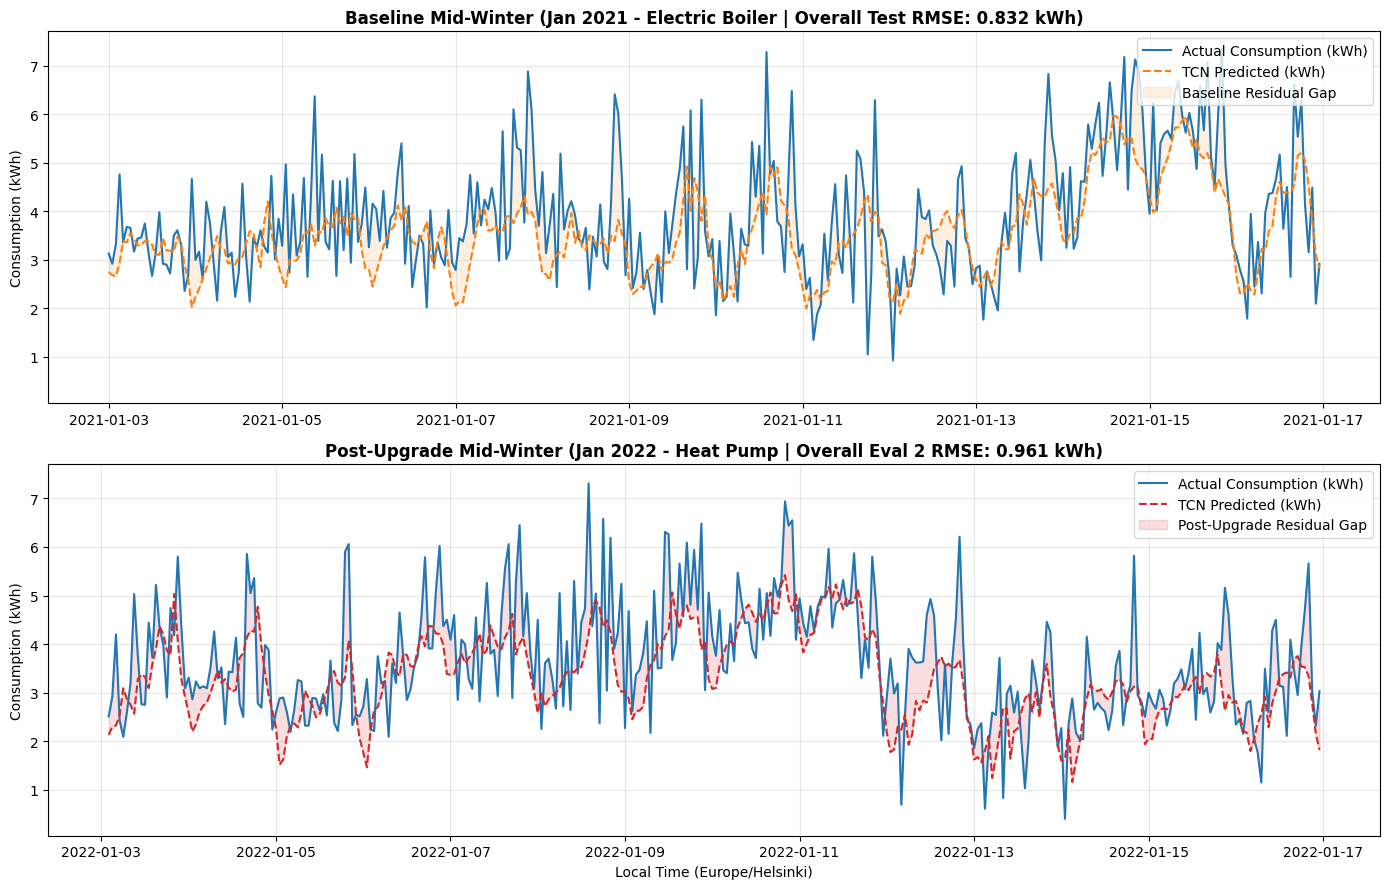

In [5]:
import matplotlib.pyplot as plt
import numpy as np
import torch

def get_predictions_and_timestamps(model, loader, df_source, seq_len=48):
    model.eval()
    preds, actuals = [], []
    with torch.no_grad():
        for x_batch, y_batch in loader:
            out = model(x_batch.to(device))
            preds.append(out.cpu().numpy())
            actuals.append(y_batch.numpy())
            
    preds = (np.concatenate(preds).flatten()) * cons_std + cons_mean
    actuals = (np.concatenate(actuals).flatten()) * cons_std + cons_mean
    timestamps = df_source.index[seq_len : seq_len + len(preds)].tz_convert('Europe/Helsinki')
    return timestamps, actuals, preds

test_ts, test_act, test_pred = get_predictions_and_timestamps(model, test_loader, test_df, SEQ_LEN)
eval2_ts, eval2_act, eval2_pred = get_predictions_and_timestamps(model, eval2_loader, eval2_df, SEQ_LEN)

jan21_mask = (test_ts >= '2021-01-03') & (test_ts < '2021-01-17')
jan22_mask = (eval2_ts >= '2022-01-03') & (eval2_ts < '2022-01-17')

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharey=True)

# Panel 1: Mid-Winter Baseline (Jan 2021 - Electric Boiler)
axes[0].plot(test_ts[jan21_mask], test_act[jan21_mask], label='Actual Consumption (kWh)', color='#1f77b4', linewidth=1.5)
axes[0].plot(test_ts[jan21_mask], test_pred[jan21_mask], label='TCN Predicted (kWh)', color='#ff7f0e', linestyle='--', linewidth=1.5)
axes[0].fill_between(
    test_ts[jan21_mask], test_act[jan21_mask], test_pred[jan21_mask],
    color='#ff7f0e', alpha=0.12, label='Baseline Residual Gap'
)
axes[0].set_title('Baseline Mid-Winter (Jan 2021 - Electric Boiler | Overall Test RMSE: 0.832 kWh)', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Consumption (kWh)')
axes[0].legend(loc='upper right')
axes[0].grid(True, alpha=0.3)

# Panel 2: Mid-Winter Post-Upgrade (Jan 2022 - Heat Pump)
axes[1].plot(eval2_ts[jan22_mask], eval2_act[jan22_mask], label='Actual Consumption (kWh)', color='#1f77b4', linewidth=1.5)
axes[1].plot(eval2_ts[jan22_mask], eval2_pred[jan22_mask], label='TCN Predicted (kWh)', color='#d62728', linestyle='--', linewidth=1.5)
axes[1].fill_between(
    eval2_ts[jan22_mask], eval2_act[jan22_mask], eval2_pred[jan22_mask],
    color='#d62728', alpha=0.15, label='Post-Upgrade Residual Gap'
)
axes[1].set_title('Post-Upgrade Mid-Winter (Jan 2022 - Heat Pump | Overall Eval 2 RMSE: 0.961 kWh)', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Local Time (Europe/Helsinki)')
axes[1].set_ylabel('Consumption (kWh)')
axes[1].legend(loc='upper right')
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('tcn_concept_drift_comparison.png', dpi=300)
plt.show()